# 01 — Base de Conhecimento, Busca Híbrida (RAG) e Varredura de Limiar

Este notebook documenta:
1. A tabela completa dos 16 trechos curados (`base/knowledge_base.jsonl`) com fonte e categoria.
2. A avaliação determinística da recuperação semântica + lexical (`Recall@1`, `Recall@3`, `MRR@3`).
3. A justificativa empírica do limiar de similaridade (`0.30`) por meio da varredura e gráfico de compensação.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common import DEFAULT_RETRIEVAL_THRESHOLD, DIR_ASSETS, DIR_BASE, DIR_EVAL, load_jsonl

kb = load_jsonl(DIR_BASE / 'knowledge_base.jsonl')
df_kb = pd.DataFrame(kb)[['chunk_id', 'categoria', 'titulo', 'fonte']]
print(f'Total de trechos curados: {len(df_kb)}')
display(df_kb)

Total de trechos curados: 16


,chunk_id,categoria,titulo,fonte
0,LEI-17794-ART05,legislacao_sp,Competência sobre árvores em áreas públicas de...,Lei Municipal SP nº 17.794/2022 (Arborização U...
1,LEI-17794-ART18,legislacao_sp,Manejo de árvore em imóvel particular (área in...,"Lei Municipal SP nº 17.794/2022, Art. 18"
2,DEC-61859-PRZ,legislacao_sp,Regulamentação e abertura de protocolos munici...,Decreto Municipal SP nº 61.859/2022
3,SP156-ROTINA,atendimento_municipal,Solicitação preventiva de poda ou vistoria em ...,Portal SP156 — Prefeitura de São Paulo
4,ENEL-EMERG-01,emergencia_eletrica,Emergência elétrica envolvendo árvore e fiação,Enel Distribuição São Paulo — Canal de Emergência
5,ENEL-RELAC-02,atendimento_concessionaria,Atendimento comercial e acompanhamento não eme...,Enel Distribuição São Paulo — Central de Relac...
6,BOMBEIROS-193,emergencia_vida,Atendimento de emergência com risco imediato à...,Corpo de Bombeiros da Polícia Militar do Estad...
7,DEFESA-CIVIL-199,emergencia_climatica,"Ocorrências de tempestade, queda de árvore e i...",Defesa Civil Municipal de São Paulo (199)
8,SEGURANCA-FIACAO,seguranca_operacional,Conduta de segurança diante de fio caído ou ve...,Manual de Segurança com Rede Elétrica — Defesa...
9,SVMA-MANUAL-PODA,norma_tecnica,Prioridade à adequação da infraestrutura antes...,Manual Técnico de Poda de Árvores — PMSP / SVMA


,threshold,recall_at_1,recall_at_3,mrr_at_3,false_refusal_rate,oos_refusal_accuracy,balanced_score
0,0.20,0.6818,0.9545,0.8030,0.0000,0.000,0.4773
1,0.25,0.6818,0.9545,0.8030,0.0000,0.125,0.5398
2,0.30,0.6818,0.9545,0.8030,0.0000,0.125,0.5398
3,0.35,0.6818,0.9091,0.7803,0.0000,0.250,0.5795
4,0.40,0.6818,0.8636,0.7652,0.0000,0.250,0.5568
5,0.45,0.6818,0.8182,0.7500,0.0455,0.500,0.6591
6,0.50,0.6818,0.8182,0.7500,0.1364,0.500,0.6591
7,0.55,0.6818,0.7273,0.7045,0.2273,0.625,0.6761
8,0.60,0.5909,0.6364,0.6136,0.3636,0.875,0.7557
9,0.65,0.3636,0.4091,0.3864,0.5909,0.875,0.6420


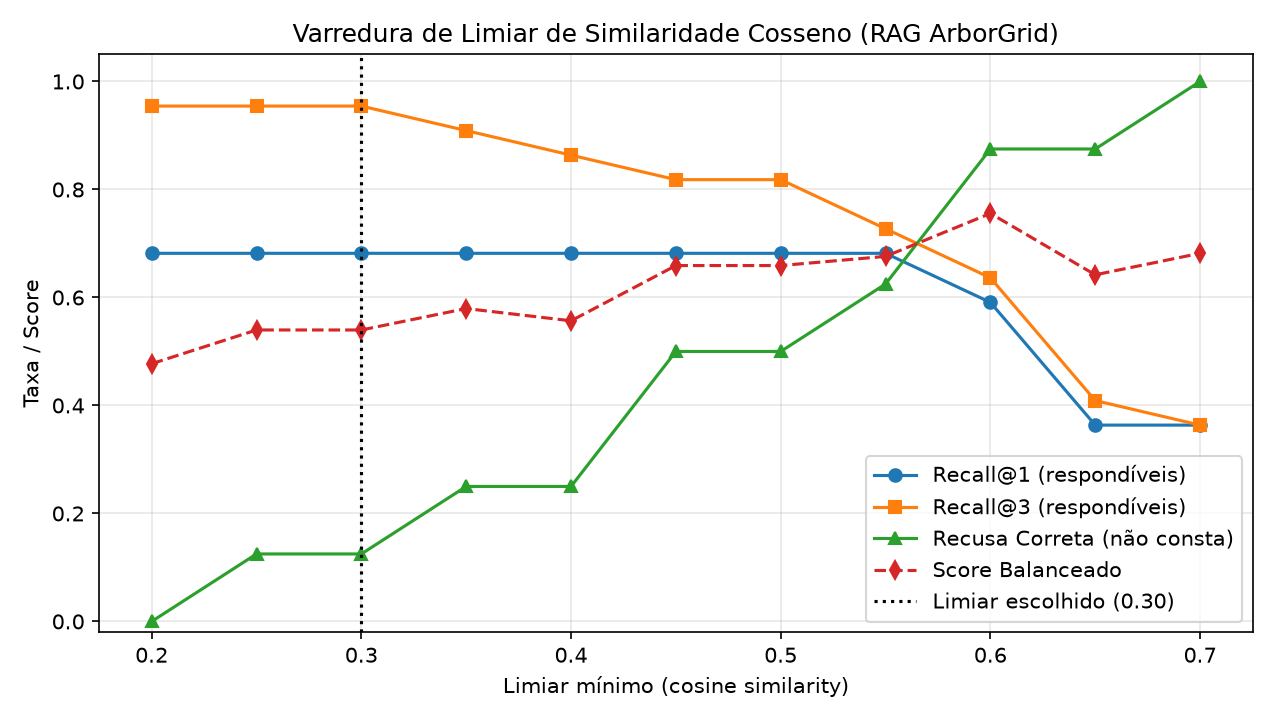

In [2]:
REEXECUTAR_BUSCA = False  # Altere para True para recalcular embeddings em tempo de execução

if REEXECUTAR_BUSCA or not (DIR_EVAL / 'retrieval_threshold_sweep.csv').exists():
    from scripts.eval_retrieval import main as run_eval
    run_eval()

df_sweep = pd.read_csv(DIR_EVAL / 'retrieval_threshold_sweep.csv')
display(df_sweep)
display(Image(filename=str(DIR_ASSETS / 'retrieval_threshold_sweep.png')))

### Decisão: Limiar de Similaridade em `0.30`
Pela curva acima, **`0.30`** zera a recusa indevida (`false_refusal_rate = 0.0000`) mantendo `Recall@1 = 0.6818`, `Recall@3 = 0.9545` e `MRR@3 = 0.8030`.

In [3]:
report = json.loads((DIR_EVAL / 'retrieval_report.json').read_text(encoding='utf-8'))
print('Limiar escolhido:', DEFAULT_RETRIEVAL_THRESHOLD)
print('Métricas no limiar escolhido:', report['chosen_metrics'])

Limiar escolhido: 0.3
Métricas no limiar escolhido: {'threshold': 0.3, 'recall_at_1': 0.6818, 'recall_at_3': 0.9545, 'mrr_at_3': 0.803, 'false_refusal_rate': 0.0, 'oos_refusal_accuracy': 0.125, 'balanced_score': 0.5398}
